[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_weekday/BA_L5_weekday.ipynb)

# BA_L5_weekday: The USDC/USDT Peg by Day of the Week

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Mean absolute deviation of USDC priced in USDT and the share of hours with a deviation of at least 15 basis points, by day of the week, hourly, January 2022 to 23 October 2026, with and without the Silicon Valley Bank (SVB) days of 10-14 March 2023. Data: EODHD hourly aggregated prices.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

Redemption at par runs through the issuer's banks, which are closed at weekends. The chart compares, by day of the week, the mean absolute deviation $|d_t|$ of USDC priced in USDT, in basis points (bp; 1 bp = 0.01%),

$$ d_t = 10^4\left(\frac{P_t^{\mathrm{USDC}}}{P_t^{\mathrm{USDT}}} - 1\right), $$

and the share of hours with $|d_t| \geq 15$ bp (breach hours), with and without the Silicon Valley Bank (SVB) days of 10–14 March 2023. All times are Coordinated Universal Time (UTC).

**Data:** EOD Historical Data (EODHD) hourly closing prices, January 2022 to 23 October 2026.

In [5]:
H = pd.concat({'USDC': hourly('USDC-USD.CC'), 'USDT': hourly('USDT-USD.CC'), 'DAI': hourly('DAI-USD.CC'),
               'BTC': hourly('BTC-USD.CC')}, axis=1)
H = H.reindex(pd.date_range('2022-01-01 00:00', '2026-10-23 23:00', freq='h'))   # regular hourly grid, lecture sample
dh = 1e4 * (H['USDC'] / H['USDT'] - 1)                                             # USDC priced in USDT, bp
print(f'hourly grid: {H.index[0]} to {H.index[-1]} UTC, {len(H)} hours; '
      f'hours with USDC or USDT missing: {100 * H[["USDC", "USDT"]].isna().any(axis=1).mean():.2f}%')

hourly grid: 2022-01-01 00:00:00 to 2026-10-23 23:00:00 UTC, 42168 hours; hours with USDC or USDT missing: 2.80%


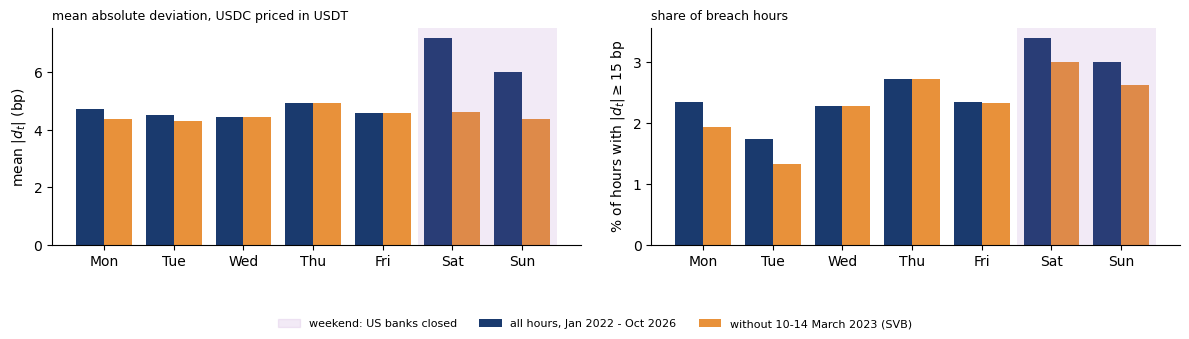

In [6]:
a_ = dh.abs()
svb_days = (a_.index >= '2023-03-10') & (a_.index < '2023-03-15')
wkend = a_.index.dayofweek >= 5
dname = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']


def by_dow(m):
    # mean |d| and % of breach hours by day of the week, on the hours selected by m
    x = a_[m]
    return x.groupby(x.index.dayofweek).mean(), 100 * (x >= 15).groupby(x.index.dayofweek).sum() / x.notna().groupby(x.index.dayofweek).sum()


m_all, b_all = by_dow(np.ones(len(a_), bool))
m_ex, b_ex = by_dow(~svb_days)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
x_ = np.arange(7)
ax[0].bar(x_ - 0.2, m_all.values, width=0.4, color=BLUE, label='all hours, Jan 2022 - Oct 2026')
ax[0].bar(x_ + 0.2, m_ex.values, width=0.4, color=BTC, label='without 10-14 March 2023 (SVB)')
ax[1].bar(x_ - 0.2, b_all.values, width=0.4, color=BLUE)
ax[1].bar(x_ + 0.2, b_ex.values, width=0.4, color=BTC)
ax[0].set_ylabel(r'mean $|d_t|$ (bp)'); ax[1].set_ylabel(r'% of hours with $|d_t| \geq 15$ bp')
ax[0].set_title('mean absolute deviation, USDC priced in USDT', fontsize=9, loc='left'); ax[1].set_title('share of breach hours', fontsize=9, loc='left')
for a2 in ax:
    a2.set_xticks(x_); a2.set_xticklabels(dname); a2.axvspan(4.5, 6.5, color=ETH, alpha=0.12, lw=0)
ax[0].fill_between([], [], color=ETH, alpha=0.12, label='weekend: US banks closed')
save(fig, 'ba_l5_weekday', 0.15, ncol=3)

## Key numbers

In [7]:
def share15(m):
    return 100 * (a_[m] >= 15).sum() / a_[m].notna().sum()


print(f'mean |d|: weekend {a_[wkend].mean():.2f} bp, weekday {a_[~wkend].mean():.2f} bp')
print(f'without the SVB days: weekend {a_[wkend & ~svb_days].mean():.2f} bp, weekday {a_[~wkend & ~svb_days].mean():.2f} bp')
print(f'breach hours without the SVB days: weekend {share15(wkend & ~svb_days):.2f}%, weekday {share15(~wkend & ~svb_days):.2f}%')
pd.DataFrame({'mean |d| (bp)': m_all.values, 'mean |d| without SVB (bp)': m_ex.values,
              '% breach hours': b_all.values, '% breach hours without SVB': b_ex.values}, index=dname).round(2)

mean |d|: weekend 6.60 bp, weekday 4.64 bp
without the SVB days: weekend 4.50 bp, weekday 4.53 bp
breach hours without the SVB days: weekend 2.80%, weekday 2.12%


,mean |d| (bp),mean |d| without SVB (bp),% breach hours,% breach hours without SVB
Mon,4.72,4.37,2.34,1.93
Tue,4.50,4.31,1.74,1.33
Wed,4.46,4.46,2.28,2.28
Thu,4.94,4.94,2.73,2.73
Fri,4.57,4.57,2.35,2.32
Sat,7.18,4.61,3.39,2.99
Sun,6.02,4.39,3.00,2.62


**How to read it:** with the SVB days the weekend mean is 6.6 bp against 4.6 bp on weekdays; without them both are 4.5 bp, so one weekend makes the whole difference in the mean.
Breach hours are a little more frequent at weekends (2.8% against 2.1% of hours). Hours are autocorrelated, so this is a comparison of shares, not a test.